In [137]:
# Задача №1

In [138]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка отображения графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 7)

# Пути к файлам
path_customers = "/mnt/HC_Volume_18315164/home-jupyter/jupyter-igor-markov-hrt6876/FINAL//olist_customers_dataset.csv"
path_orders = "/mnt/HC_Volume_18315164/home-jupyter/jupyter-igor-markov-hrt6876/FINAL//olist_orders_dataset.csv"

# Загрузка данных
customers = pd.read_csv(path_customers, encoding='ISO-8859-1')
orders = pd.read_csv(path_orders, encoding='ISO-8859-1')

In [139]:
# Анализ распределения статусов заказов
print("Распределение статусов заказов:")
print(orders['order_status'].value_counts())
print("\nВсего заказов:", len(orders))

Распределение статусов заказов:
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: order_status, dtype: int64

Всего заказов: 99441


In [140]:
# Оставляем только доставленные заказы для корректного расчета Retention
valid_orders = orders[orders['order_status'] == 'delivered'].copy()

# Привожу даты к формату datetime
valid_orders['order_purchase_timestamp'] = pd.to_datetime(valid_orders['order_purchase_timestamp'])

# Объединяю с таблицей клиентов для получения уникального идентификатора клиента (customer_unique_id)
# Использую customer_unique_id, так как customer_id идентифицирует конкретный заказ, а не клиента
valid_orders = valid_orders.merge(
    customers[['customer_id', 'customer_unique_id']], 
    on='customer_id', 
    how='left'
)

# Проверка отсутствия пропусков после объединения
print("Пропусков в customer_unique_id:", valid_orders['customer_unique_id'].isna().sum())

Пропусков в customer_unique_id: 0


In [141]:
# Создание колонки с месяцем совершения заказа
valid_orders['order_month'] = valid_orders['order_purchase_timestamp'].dt.to_period('M')

# Определение месяца первой покупки для каждого клиента (месяц когорты)
first_purchase = valid_orders.groupby('customer_unique_id')['order_purchase_timestamp'].min().reset_index()
first_purchase.columns = ['customer_unique_id', 'cohort_month']
first_purchase['cohort_month'] = first_purchase['cohort_month'].dt.to_period('M')

# Присоединение данных о когорте к основному датафрейму
valid_orders = valid_orders.merge(first_purchase, on='customer_unique_id', how='left')

# Вывод примера данных
valid_orders[['customer_unique_id', 'order_month', 'cohort_month']].head()

,customer_unique_id,order_month,cohort_month
0,7c396fd4830fd04220f754e42b4e5bff,2017-10,2017-09
1,af07308b275d755c9edb36a90c618231,2018-07,2018-07
2,3a653a41f6f9fc3d2a113cf8398680e8,2018-08,2018-08
3,7c142cf63193a1473d2e66489a9ae977,2017-11,2017-11
4,72632f0f9dd73dfee390c9b22eb56dd6,2018-02,2018-02


In [142]:
# Вычисление разницы в месяцах между текущим заказом и первой покупкой клиента
# Нулевой индекс соответствует месяцу первой покупки
valid_orders['cohort_index'] = valid_orders['order_month'].astype(int) - valid_orders['cohort_month'].astype(int)

# Проверка минимального значения индекса
print("Минимальный индекс когорты:", valid_orders['cohort_index'].min())

Минимальный индекс когорты: 0


In [143]:
# Агрегация данных: подсчет количества уникальных клиентов в каждой когорте по месяцам
cohort_data = valid_orders.groupby(['cohort_month', 'cohort_index'])['customer_unique_id'].nunique().reset_index()

# Построение сводной таблицы (Pivot Table): строки — когорты, столбцы — месяцы жизни
cohort_pivot = cohort_data.pivot(index='cohort_month', columns='cohort_index', values='customer_unique_id')

# Расчет Retention Rate: деление значений каждой строки на размер когорты (месяц 0)
cohort_size = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_size, axis=0)

# Округление значений для удобства восприятия
retention_matrix = retention_matrix.round(4)

# Вывод первых строк матрицы
retention_matrix.head()

cohort_index,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,19,20
cohort_month,,,,,,,,,,,,,,,,,,,,
2016-09,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2016-10,1.0,NaN,NaN,NaN,NaN,NaN,0.0038,NaN,NaN,0.0038,NaN,0.0038,NaN,0.0038,NaN,0.0038,NaN,0.0038,0.0076,0.0076
2016-12,1.0,1.0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01,1.0,0.0028,0.0028,0.0014,0.0042,0.0014,0.0042,0.0014,0.0014,NaN,0.0042,0.0014,0.0070,0.0042,0.0014,0.0014,0.0028,0.0042,0.0014,NaN
2017-02,1.0,0.0018,0.0031,0.0012,0.0043,0.0012,0.0025,0.0018,0.0012,0.0018,0.0012,0.0031,0.0012,0.0018,0.0012,0.0006,0.0006,0.0018,NaN,NaN


In [144]:
# Расчет медианного Retention для 1-го месяца
retention_month_1 = retention_matrix[1].dropna()
median_retention_1 = retention_month_1.median()
print(f"Медианный Retention 1-го месяца: {median_retention_1:.2%}")

# Поиск когорты с максимальным Retention на 3-й месяц
retention_month_3 = retention_matrix[3].dropna()
max_cohort = retention_month_3.idxmax()
max_value = retention_month_3.max()
print(f"Когорта с максимальным Retention на 3-й месяц: {max_cohort}")
print(f"Значение Retention: {max_value:.2%}")

Медианный Retention 1-го месяца: 0.51%
Когорта с максимальным Retention на 3-й месяц: 2017-06
Значение Retention: 0.43%


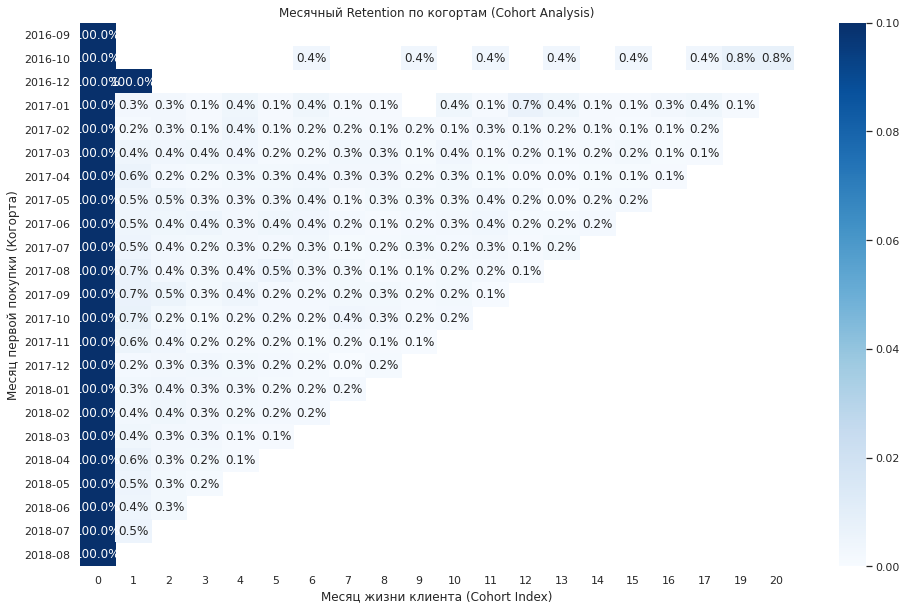

In [145]:
plt.figure(figsize=(16, 10))
plt.title('Месячный Retention по когортам (Cohort Analysis)')

# Построение тепловой карты
sns.heatmap(retention_matrix, 
            annot=True, 
            fmt='.1%', 
            cmap='Blues', 
            vmin=0, vmax=0.1)

plt.ylabel('Месяц первой покупки (Когорта)')
plt.xlabel('Месяц жизни клиента (Cohort Index)')
plt.show()

In [146]:
# Задача №2

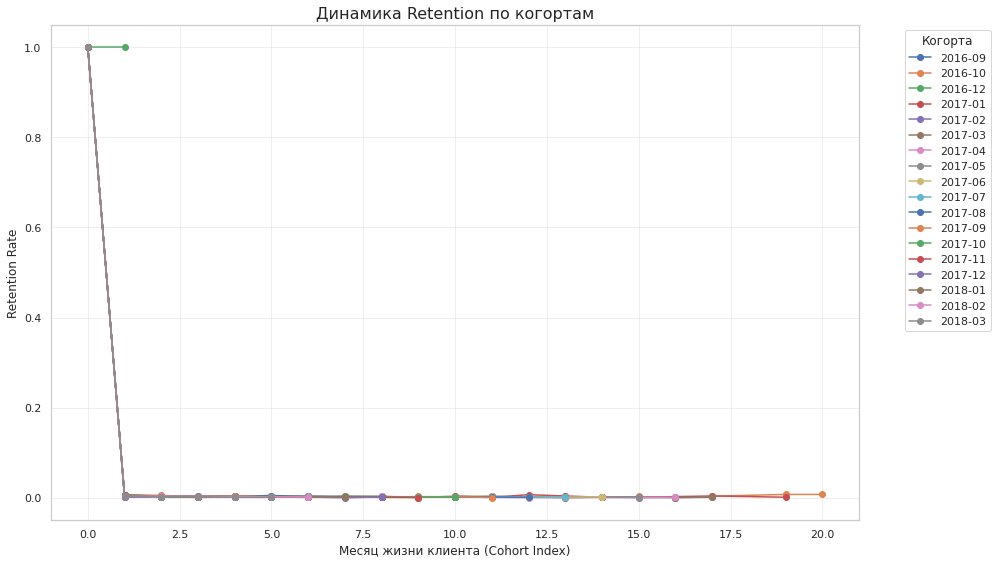

In [147]:
# Визуализация динамики Retention по когортам
plt.figure(figsize=(14, 8))

# Исключаем последние 5 когорт, так как для них нет полных данных за весь период
for cohort in retention_matrix.index[:-5]:
    plt.plot(retention_matrix.columns, retention_matrix.loc[cohort], marker='o', label=str(cohort))

plt.title('Динамика Retention по когортам', fontsize=16)
plt.xlabel('Месяц жизни клиента (Cohort Index)', fontsize=12)
plt.ylabel('Retention Rate', fontsize=12)
plt.legend(title='Когорта', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [148]:
# Подсчет количества заказов на одного уникального клиента
customer_orders_count = valid_orders.groupby('customer_unique_id')['order_id'].nunique().reset_index()
customer_orders_count.columns = ['customer_unique_id', 'order_count']

# Вывод распределения количества заказов
print("Распределение количества заказов на клиента:")
print(customer_orders_count['order_count'].value_counts().head(10))

# Расчет доли клиентов с повторными покупками
repeat_customers = customer_orders_count[customer_orders_count['order_count'] > 1]
repeat_rate = len(repeat_customers) / len(customer_orders_count)
print(f"\nДоля клиентов с повторными покупками: {repeat_rate:.2%}")

Распределение количества заказов на клиента:
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: order_count, dtype: int64

Доля клиентов с повторными покупками: 3.00%


Топ-10 клиентов по количеству заказов:
                     customer_unique_id  order_count
51431  8d50f5eadf50201ccdcedfb9e2ac8455           15
22779  3e43e6105506432c953e165fb2acf44c            9
36706  6469f99c1f9dfae7733b25662e7f1782            7
73921  ca77025e7201e3b30c44b472ff346268            7
10060  1b6c7548a2a1f9037c1fd3ddfed95f33            7
87885  f0e310a6839dce9de1638e0fe5ab282a            6
26257  47c1a3033b8b77b3ab6e109eb4d5fdf3            6
6964   12f5d6e1cbf93dafd9dcc19095df0b3d            6
36500  63cfc61cee11cbe306bff5857d00bfe4            6
80538  dc813062e0fc23409cd255f7f53c7074            6


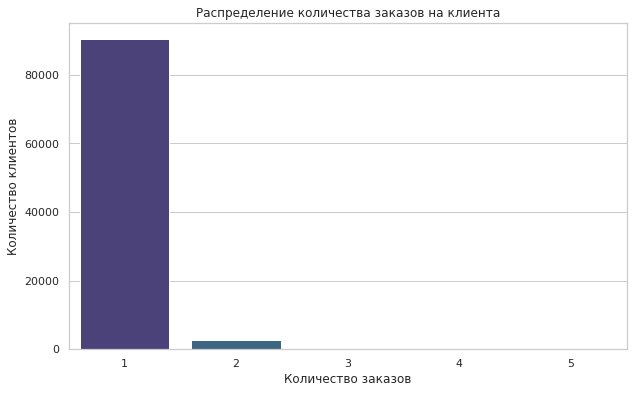

In [149]:
# Вывод топ-10 клиентов по количеству заказов
top_customers = customer_orders_count.sort_values(by='order_count', ascending=False).head(10)
print("Топ-10 клиентов по количеству заказов:")
print(top_customers)

# Визуализация распределения частоты заказов (ограничение до 5 заказов)
plt.figure(figsize=(10, 6))
sns.countplot(data=customer_orders_count[customer_orders_count['order_count'] <= 5], 
              x='order_count', palette='viridis')
plt.title('Распределение количества заказов на клиента')
plt.xlabel('Количество заказов')
plt.ylabel('Количество клиентов')
plt.show()

In [150]:
# Переводим месяц в текст, чтобы графики могли его отобразить
valid_orders['order_month'] = valid_orders['order_month'].astype(str)

In [151]:
# Задача №3

In [152]:
# Подгружаем таблицу с товарами, чтобы узнать цены
path_order_items = (
    "/mnt/HC_Volume_18315164/home-jupyter/"
    "jupyter-igor-markov-hrt6876/FINAL//olist_order_items_dataset.csv"
)
order_items = pd.read_csv(path_order_items, encoding='ISO-8859-1')

# Склеиваем заказы с товарами по order_id
orders_with_items = valid_orders.merge(
    order_items[['order_id', 'price']], 
    on='order_id', 
    how='left'
)

# Считаем, сколько всего денег принес каждый заказ
order_revenue = orders_with_items.groupby('order_id')['price'].sum().reset_index()
order_revenue.columns = ['order_id', 'revenue']

# Добавляем эту сумму в основную таблицу
valid_orders = valid_orders.merge(order_revenue, on='order_id', how='left')

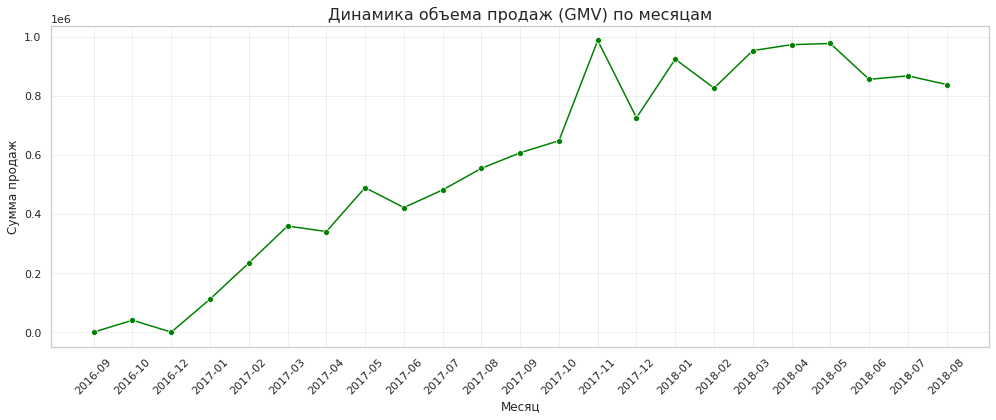

In [153]:
# Считаем выручку по месяцам
monthly_gmv = valid_orders.groupby('order_month')['revenue'].sum().reset_index()

# Строим график
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_gmv, x='order_month', y='revenue', marker='o', color='green')
plt.title('Динамика объема продаж (GMV) по месяцам', fontsize=16)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Сумма продаж', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

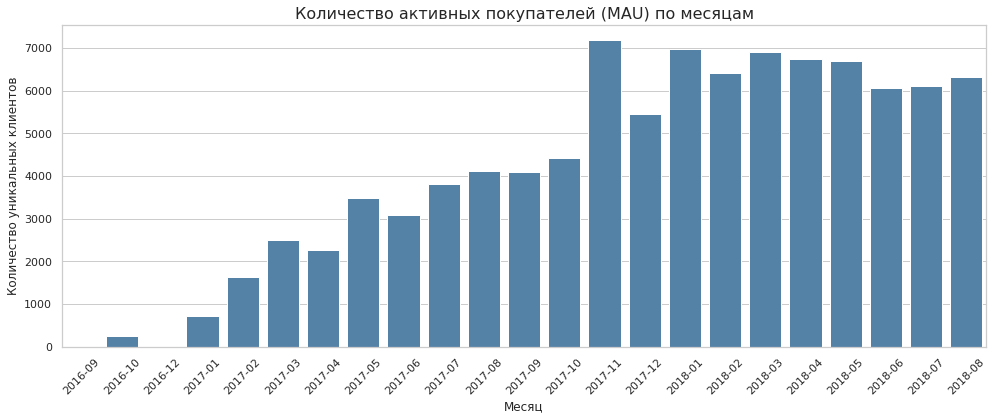

In [154]:
# Считаем, сколько уникальных клиентов покупали каждый месяц
monthly_mau = valid_orders.groupby('order_month')['customer_unique_id'].nunique().reset_index()
monthly_mau.columns = ['order_month', 'mau']

# Строим график
plt.figure(figsize=(14, 6))
sns.barplot(data=monthly_mau, x='order_month', y='mau', color='steelblue')
plt.title('Количество активных покупателей (MAU) по месяцам', fontsize=16)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('Количество уникальных клиентов', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

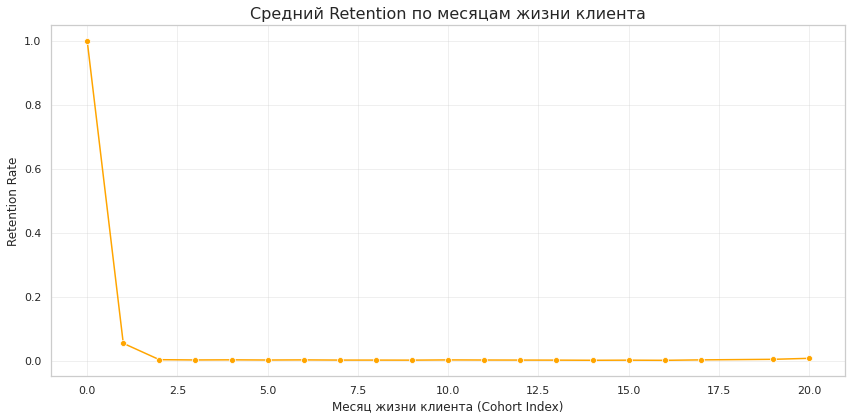

In [155]:
# Берем средний Retention по всем когортам для каждого месяца жизни
avg_retention = retention_matrix.mean(axis=0).reset_index()
avg_retention.columns = ['cohort_index', 'avg_retention']

# Строим график
plt.figure(figsize=(12, 6))
sns.lineplot(data=avg_retention, x='cohort_index', y='avg_retention', marker='o', color='orange')
plt.title('Средний Retention по месяцам жизни клиента', fontsize=16)
plt.xlabel('Месяц жизни клиента (Cohort Index)', fontsize=12)
plt.ylabel('Retention Rate', fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

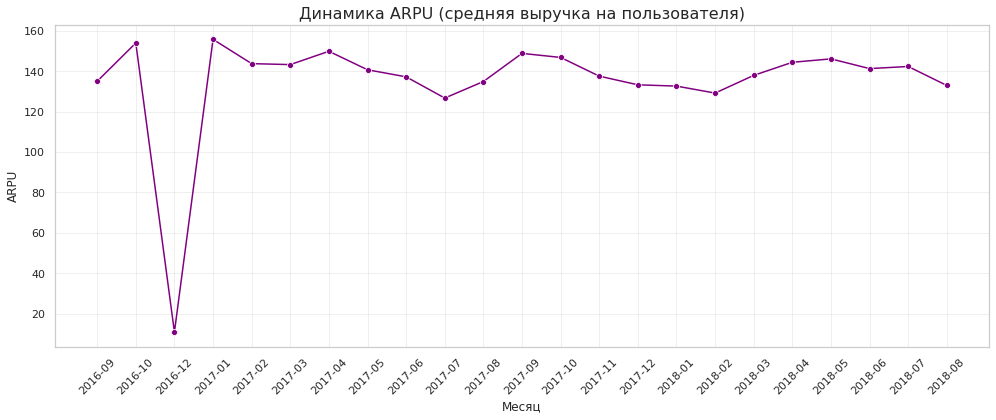

In [156]:
# Считаем выручку и количество клиентов по месяцам в одной таблице
monthly_stats = valid_orders.groupby('order_month').agg(
    total_revenue=('revenue', 'sum'),
    unique_customers=('customer_unique_id', 'nunique')
).reset_index()

# Делим выручку на клиентов, чтобы получить ARPU
monthly_stats['arpu'] = monthly_stats['total_revenue'] / monthly_stats['unique_customers']

# Строим график
plt.figure(figsize=(14, 6))
sns.lineplot(data=monthly_stats, x='order_month', y='arpu', marker='o', color='purple')
plt.title('Динамика ARPU (средняя выручка на пользователя)', fontsize=16)
plt.xlabel('Месяц', fontsize=12)
plt.ylabel('ARPU', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [157]:
# Задача №4

In [158]:
# Берем данные за июнь 2017 года
june_orders = valid_orders[valid_orders['order_month'] == '2017-06']

# Считаем, сколько уникальных клиентов было в июне
june_customers = june_orders['customer_unique_id'].nunique()
print(f"Клиентов в июне 2017: {june_customers}")

# Считаем, сколько из них вернулись за повторным заказом (используем медианный Retention из Задачи 1)
# Конверсия в повторный заказ равна медианному retention 1-го месяца
conversion_rate = median_retention_1
repeat_orders = june_customers * conversion_rate
print(f"Ожидаемое количество повторных заказов: {repeat_orders:.0f}")

Клиентов в июне 2017: 3076
Ожидаемое количество повторных заказов: 16


In [159]:
# Функция для перевода числа в балл Impact по таблице из задания
def get_impact_score(value):
    if value <= 50:
        return 1
    elif value <= 150:
        return 2
    elif value <= 350:
        return 3
    elif value <= 750:
        return 4
    elif value <= 1550:
        return 5
    elif value <= 3150:
        return 6
    elif value <= 6350:
        return 7
    elif value <= 12750:
        return 8
    elif value <= 25550:
        return 9
    else:
        return 10

In [160]:
# Считаем Impact для наших данных
impact_score = get_impact_score(repeat_orders)
print(f"Impact для гипотез: {impact_score}")

Impact для гипотез: 1


In [161]:
# Создаем таблицу с гипотезами
hypotheses = pd.DataFrame({
    'Гипотеза': [
        'Исправить баг в системе процессинга заказов',
        'Сократить время до отгрузки заказа',
        'Создать новый способ оплаты для повторных заказов'
    ],
    'Impact': [impact_score, impact_score, impact_score],
    'Confidence': [8, 10, 5],
    'Ease': [6, 4, 9]
})

# Считаем ICE
hypotheses['ICE'] = hypotheses['Impact'] * hypotheses['Confidence'] * hypotheses['Ease']

# Сортируем по убыванию ICE
hypotheses = hypotheses.sort_values(by='ICE', ascending=False).reset_index(drop=True)

# Выводим результат
print(hypotheses)
 

                                            Гипотеза  Impact  Confidence  \
0        Исправить баг в системе процессинга заказов       1           8   
1  Создать новый способ оплаты для повторных заказов       1           5   
2                 Сократить время до отгрузки заказа       1          10   

   Ease  ICE  
0     6   48  
1     9   45  
2     4   40  


In [162]:
# Задача №5

# Метрики для проверки гипотезы
Проверяем гипотезу: «Если починить баг в процессинге заказов, клиенты перестанут сталкиваться с отменами, и доставок станет больше».
Для A/B-теста я разбил метрики на три группы — целевую, прокси и охранную.
1. Целевая метрика: доля доставленных заказов.
Здесь всё просто — это то, ради чего мы вообще затеяли изменения. Если баг реально мешал заказам доходить до клиента, то после фикса эта доля обязана пойти вверх. Если она не изменится, значит, гипотеза неверна, и копать надо в другом месте. Минус этой метрики в том, что доставка занимает дни, а иногда и недели. Ждать результата долго.
2. Прокси-метрика: доля заказов, которые сразу ушли в обработку.
Это мой «быстрый сигнал». Ждать доставки неделями, чтобы понять, сработал ли фикс, — слишком долго. А вот перевод заказа из статуса created в approved или processing происходит почти мгновенно после оплаты. Если баг мешал заказам на старте, мы увидим рост этой метрики уже через пару дней после запуска теста. Это позволит принять решение быстро, не дожидаясь финала.
3. Guardrail-метрика: средний чек. 
Это средняя сумма, которую клиент оставляет за один заказ. Почему я её выбрал: Это наша проверка на всякий случай. Мы не хотим, чтобы доставок стало больше, но за счёт дешёвых товаров, которые раньше просто отменялись. Если средний чек резко упадёт, значит, бизнес теряет деньги, хотя доставок стало больше. Это будет сигналом, что что-то пошло не так. Как я сделаю вывод: Если доля доставок выросла, доля заказов, ушедших в обработку, увеличилась, а средний чек не упал — гипотеза сработала. Если хотя бы один пункт сломался, нужно разбираться почему.)

In [163]:
# Задача №6

Отчет для Пети
 
Привет, Петя! Я разобрался с данными по нашему маркетплейсу. Собрал главное, без лишней теории — чтобы ты сразу увидел, что происходит и куда нужно двигаться.
 
В чём наша проблема...
 
Мы хорошо привлекаем людей, но плохо их удерживаем. Клиент покупает один раз и уходит. Из-за этого выручка стоит на месте, хотя на привлечение мы тратим ресурсы. Если ничего не менять, выходить на новые рынки — рискованно: мы просто будем сливать деньги на привлечение, не получая отдачи.
 
Что я увидел в данных
 
Первое. Клиенты быстро остывают. Я посмотрел, как ведут себя разные группы клиентов с момента первой покупки. Картина одинаковая: в первый месяц отток огромный, дальше остаётся небольшая доля тех, кто возвращается. Это значит, что продукт решает разовую задачу, но не становится привычкой.
 
Второе. Готовность к масштабированию пока не подтверждена. Если по-простому — Product/Market Fit у нас не сформирован. Людям нравится покупать, но причина возвращаться снова пока неочевидна.
 
Третье. Я определил пять метрик, за которыми тебе стоит следить как за ориентирами:
• Объём продаж — общий рост бизнеса.
• Активная аудитория — сколько людей покупает каждый месяц.
• Доля новых клиентов — насколько хорошо мы привлекаем новую аудиторию.
• Удержание — сколько клиентов возвращается.
• Средняя выручка на клиента — сколько денег приносит один пользователь. 
Эти пять показателей — твоя приборная 
панель. Если хотя бы один проседает — есть повод разбираться.
 
Отдельно отмечу: для расчёта денежных метрик я дополнительно подключил данные о товарах из файла olist_order_items_dataset.csv — там есть цены, которых нет в основных таблицах.
 
Что я предлагаю чинить первым делом
 
Я сформулировал три гипотезы, как улучшить ситуацию, и вместе с командой прогнал их по методике ICE. Суть простая: смотрим на три вещи — насколько сильно идея повлияет на бизнес, насколько мы уверены в успехе и насколько просто её реализовать. В итоге победила гипотеза про исправление бага в процессинге заказов. Она даёт максимальный эффект при минимальных затратах.
 
Как мы поймём, что сработало
 
Для проверки этой гипотезы я собрал набор метрик:
• Главная цель: доля доставленных заказов. Должна вырасти.
• Быстрый сигнал: как быстро заказ переходит в статус «в обработке». Это видно почти сразу, не дожидаясь доставки.
• Финансовая страховка: средний чек. Если доставок станет больше, но за счёт дешёвых товаров, которые раньше отсеивались, — мы потеряем деньги. Средний чек упадёт — значит, фикс надо пересматривать. 
Что делать дальше
 
Первое. Чинить баг в процессинге заказов. Это быстрый и ощутимый эффект.
 
Второе. Работать над удержанием. Нужно понять, почему люди не возвращаются. Возможно, дело в ассортименте, доставке или в том, как мы общаемся с клиентом после покупки. Стоит запустить опросы или программу лояльности для тех, кто купил впервые.
 
Третье. Не масштабироваться раньше времени. Пока удержание низкое, новые рынки — это риск. Сначала нужно сделать так, чтобы текущие клиенты возвращались.
 
Итог
 
Продукт востребован, но пока не стал привычным. Самая перспективная точка роста — исправить техническую ошибку, из-за которой отменяются заказы. Если мы это сделаем и удержим клиентов, у бизнеса появится база для роста. А следить за прогрессом будем по пяти метрикам, которые я описал выше. 